# Linear algebra proofs: SymPy, Lean, supply and demand, and attention in torch

Two kinds of proof, side by side:

* **SymPy** proves an identity for one size: make every matrix entry its own symbol, expand
  lhs − rhs, and get exactly 0. That is a real proof for 2×2 or 3×3, but only for that size.
* **Lean** proves it for **every** size and checks each step by machine.

Then the same algebra runs two applications: a supply-and-demand market (a 2×2 linear system,
also solved in C with gcc) and attention in torch (softmax of a matrix product).

| # | Claim | Lean | Check here |
|---|---|---|---|
| 1 | det(AB) = det A det B, (AB)ᵀ = BᵀAᵀ, tr(AB) = tr(BA) | `det_product`, `transpose_product`, `trace_cyclic` | symbolic 2×2, 3×3 |
| 2 | a null space is closed under midpoints | `kernel_midpoint` | `nullspace()` |
| 3 | Cauchy-Schwarz | `cauchy_schwarz_2d` | Lagrange identity in 2-D and 3-D |
| 4 | P² = P ⇒ (1 − P)² = 1 − P | `complement_projection` | P = vvᵀ/vᵀv |
| 5 | market price P* = (a − c)/(b + d) | `equilibrium_price`, `demand_shift_raises_price` | SymPy + gcc |
| 6 | softmax: positive, sums to 1, shift-invariant | `softmax_pos`, `softmax_sum_one`, `softmax_shift` | torch attention |

In [1]:
import sys
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()))
import numpy as np, sympy as sp, pandas as pd, matplotlib.pyplot as plt
from IPython.display import display
sp.init_printing(use_unicode=True)
from dgs import linear_algebra_proofs as L

In [2]:
%load_ext dgs.lean_magic
%lean_reset

Lean cells cleared.


In [3]:
%%lean header
/-
Linear algebra proofs for engineering: matrices, a market model, and attention. Lean 4 + Mathlib.
Companion to notebooks/linear_algebra_proofs.ipynb and dgs/linear_algebra_proofs.py.

What is proved here:
  1. Matrix rules: det(AB) = det A det B, (AB)^T = B^T A^T, tr(AB) = tr(BA), the 2x2 det formula
  2. A kernel (null space) is a subspace: the midpoint of two solutions of A v = 0 is a solution
     (compare DispersionPhaseRetrieval.lean: the magnitude set |z| = 1 is NOT closed under midpoints)
  3. Cauchy-Schwarz in R^2, from the Lagrange identity
  4. Projections: if P P = P then (1 - P)(1 - P) = 1 - P (the complementary projection)
  5. Supply and demand: linear demand Q = a - b P and supply Q = c + d P meet at
     P* = (a - c)/(b + d); a demand shift up by delta raises P* by delta/(b + d) > 0
  6. Softmax (the attention weights): the weights are positive, sum to 1, and adding a constant
     to every score changes nothing (why torch subtracts the max before exp)

Check with (from a Lake project that depends on Mathlib):
    lake env lean LinearAlgebraProofs.lean
-/
import Mathlib.LinearAlgebra.Matrix.Determinant.Basic
import Mathlib.LinearAlgebra.Matrix.Trace
import Mathlib.LinearAlgebra.Matrix.Notation
import Mathlib.Analysis.SpecialFunctions.Exp
import Mathlib.Algebra.BigOperators.Field
import Mathlib.Tactic.LinearCombination
import Mathlib.Tactic.FieldSimp
import Mathlib.Tactic.Positivity

open Matrix

namespace LinAlg

**Lean cell `header`** (collected; compiled by `%lean_check`)
```lean
/-
Linear algebra proofs for engineering: matrices, a market model, and attention. Lean 4 + Mathlib.
Companion to notebooks/linear_algebra_proofs.ipynb and dgs/linear_algebra_proofs.py.

What is proved here:
  1. Matrix rules: det(AB) = det A det B, (AB)^T = B^T A^T, tr(AB) = tr(BA), the 2x2 det formula
  2. A kernel (null space) is a subspace: the midpoint of two solutions of A v = 0 is a solution
     (compare DispersionPhaseRetrieval.lean: the magnitude set |z| = 1 is NOT closed under midpoints)
  3. Cauchy-Schwarz in R^2, from the Lagrange identity
  4. Projections: if P P = P then (1 - P)(1 - P) = 1 - P (the complementary projection)
  5. Supply and demand: linear demand Q = a - b P and supply Q = c + d P meet at
     P* = (a - c)/(b + d); a demand shift up by delta raises P* by delta/(b + d) > 0
  6. Softmax (the attention weights): the weights are positive, sum to 1, and adding a constant
     to every score changes nothing (why torch subtracts the max before exp)

Check with (from a Lake project that depends on Mathlib):
    lake env lean LinearAlgebraProofs.lean
-/
import Mathlib.LinearAlgebra.Matrix.Determinant.Basic
import Mathlib.LinearAlgebra.Matrix.Trace
import Mathlib.LinearAlgebra.Matrix.Notation
import Mathlib.Analysis.SpecialFunctions.Exp
import Mathlib.Algebra.BigOperators.Field
import Mathlib.Tactic.LinearCombination
import Mathlib.Tactic.FieldSimp
import Mathlib.Tactic.Positivity

open Matrix

namespace LinAlg
```

## 1. Matrix rules, proved symbolically

Every entry of A and B is a separate symbol, so a zero difference holds for *all* real 2×2
(or 3×3) matrices. The determinant rule is why "a product of invertible matrices is invertible":
det(AB) ≠ 0 when both determinants are nonzero.

In [4]:
A = L.symbolic_matrix("a", 2)
display(A, sp.Eq(sp.Symbol("det A"), A.det()))
display(pd.DataFrame({"2x2": L.prove_identities(2), "3x3": L.prove_identities(3)}))

⎡a₁₁  a₁₂⎤
⎢        ⎥
⎣a₂₁  a₂₂⎦

,2x2,3x3
det(AB) = det(A) det(B),True,True
(AB)^T = B^T A^T,True,True
tr(AB) = tr(BA),True,True
det(A^T) = det(A),True,True
(AB)^-1 = B^-1 A^-1,True,True


In [5]:
%%lean matrix
/-! ## 1. Matrix rules -/

theorem det_product {n : Type*} [Fintype n] [DecidableEq n] (A B : Matrix n n ℝ) :
    (A * B).det = A.det * B.det :=
  Matrix.det_mul A B

theorem transpose_product {n : Type*} [Fintype n] (A B : Matrix n n ℝ) :
    (A * B)ᵀ = Bᵀ * Aᵀ :=
  Matrix.transpose_mul A B

theorem trace_cyclic {n : Type*} [Fintype n] (A B : Matrix n n ℝ) :
    (A * B).trace = (B * A).trace :=
  Matrix.trace_mul_comm A B

theorem det_two_by_two (a b c d : ℝ) : !![a, b; c, d].det = a * d - b * c :=
  Matrix.det_fin_two_of a b c d

**Lean cell `matrix`** (collected; compiled by `%lean_check`)
```lean
/-! ## 1. Matrix rules -/

theorem det_product {n : Type*} [Fintype n] [DecidableEq n] (A B : Matrix n n ℝ) :
    (A * B).det = A.det * B.det :=
  Matrix.det_mul A B

theorem transpose_product {n : Type*} [Fintype n] (A B : Matrix n n ℝ) :
    (A * B)ᵀ = Bᵀ * Aᵀ :=
  Matrix.transpose_mul A B

theorem trace_cyclic {n : Type*} [Fintype n] (A B : Matrix n n ℝ) :
    (A * B).trace = (B * A).trace :=
  Matrix.trace_mul_comm A B

theorem det_two_by_two (a b c d : ℝ) : !![a, b; c, d].det = a * d - b * c :=
  Matrix.det_fin_two_of a b c d
```

## 2. Midpoints: why a null space is a subspace

If Av = 0 and Aw = 0, then A((v + w)/2) = (Av + Aw)/2 = 0. Linearity is the whole proof.
Compare the phase-retrieval notebook: the set |z| = 1 fails this test (the midpoint of 1 and −1
is 0). Linear constraints are convex; magnitude constraints are not.

In [6]:
M = sp.Matrix([[1, 1, 1], [1, -1, 0]])
basis, ok = L.kernel_midpoint(M)
display(M, basis)
print("midpoint of two null vectors is null:", ok, "  |  rank + nullity =", M.rank(), "+", len(basis), "=", M.shape[1])

⎡1  1   1⎤
⎢        ⎥
⎣1  -1  0⎦

⎡⎡-1/2⎤⎤
⎢⎢    ⎥⎥
⎢⎢-1/2⎥⎥
⎢⎢    ⎥⎥
⎣⎣ 1  ⎦⎦

midpoint of two null vectors is null: True   |  rank + nullity = 2 + 1 = 3


In [7]:
%%lean kernel
/-! ## 2. The null space is closed under midpoints -/

theorem kernel_midpoint {m n : Type*} [Fintype n] (A : Matrix m n ℝ) (v w : n → ℝ)
    (hv : A *ᵥ v = 0) (hw : A *ᵥ w = 0) : A *ᵥ ((1 / 2 : ℝ) • (v + w)) = 0 := by
  rw [Matrix.mulVec_smul, Matrix.mulVec_add, hv, hw]
  simp

**Lean cell `kernel`** (collected; compiled by `%lean_check`)
```lean
/-! ## 2. The null space is closed under midpoints -/

theorem kernel_midpoint {m n : Type*} [Fintype n] (A : Matrix m n ℝ) (v w : n → ℝ)
    (hv : A *ᵥ v = 0) (hw : A *ᵥ w = 0) : A *ᵥ ((1 / 2 : ℝ) • (v + w)) = 0 := by
  rw [Matrix.mulVec_smul, Matrix.mulVec_add, hv, hw]
  simp
```

## 3. Cauchy-Schwarz from a sum of squares

|u|²|v|² − (u·v)² equals Σ (uᵢvⱼ − uⱼvᵢ)², a sum of squares, so it can't be negative. Lean's
`nlinarith` finds the same certificate when given the hint (ad − bc)² ≥ 0.

In [8]:
for n in (2, 3):
    gap, sos = L.cauchy_schwarz(n)
    display(sp.Eq(sp.factor(gap), sp.factor(sos)) if n == 2 else sos)
    print(f"n={n}: gap - sum of squares =", sp.expand(gap - sos))

n=2: gap - sum of squares = 0


n=3: gap - sum of squares = 0


In [9]:
%%lean cauchy
/-! ## 3. Cauchy-Schwarz in the plane -/

theorem cauchy_schwarz_2d (a b c d : ℝ) : (a * c + b * d) ^ 2 ≤ (a ^ 2 + b ^ 2) * (c ^ 2 + d ^ 2) := by
  nlinarith [sq_nonneg (a * d - b * c)]

**Lean cell `cauchy`** (collected; compiled by `%lean_check`)
```lean
/-! ## 3. Cauchy-Schwarz in the plane -/

theorem cauchy_schwarz_2d (a b c d : ℝ) : (a * c + b * d) ^ 2 ≤ (a ^ 2 + b ^ 2) * (c ^ 2 + d ^ 2) := by
  nlinarith [sq_nonneg (a * d - b * c)]
```

## 4. Projections

P = vvᵀ/(vᵀv) projects onto the line through v. Projecting twice changes nothing (P² = P), and
1 − P projects onto everything perpendicular. Lean proves the complement fact in any ring, so it
holds for matrices of every size, and for operators in quantum mechanics too.

In [10]:
P, props = L.projection([1, 2, 2])
display(P)
display(pd.Series(props, name="holds"))
print("eigenvalues of P:", P.eigenvals(), " (a projection only has eigenvalues 0 and 1)")

⎡1/9  2/9  2/9⎤
⎢             ⎥
⎢2/9  4/9  4/9⎥
⎢             ⎥
⎣2/9  4/9  4/9⎦

P^T = P             True
P P = P             True
(1-P)(1-P) = 1-P    True
P v = v             True
Name: holds, dtype: bool

eigenvalues of P: {1: 1, 0: 2}  (a projection only has eigenvalues 0 and 1)


In [11]:
%%lean projection
/-! ## 4. Complementary projection -/

theorem complement_projection {R : Type*} [Ring R] (P : R) (h : P * P = P) :
    (1 - P) * (1 - P) = 1 - P := by
  simp only [sub_mul, mul_sub, one_mul, mul_one, h]
  abel

**Lean cell `projection`** (collected; compiled by `%lean_check`)
```lean
/-! ## 4. Complementary projection -/

theorem complement_projection {R : Type*} [Ring R] (P : R) (h : P * P = P) :
    (1 - P) * (1 - P) = 1 - P := by
  simp only [sub_mul, mul_sub, one_mul, mul_one, h]
  abel
```

## 5. Supply and demand as a 2×2 system (photonics example)

Demand Q = a − bP and supply Q = c + dP. Written as a matrix:

[[1, b], [1, −d]] · [Q, P] = [a, c], with det = −(b + d).

The numbers are made up, for a 1550 nm DFB laser diode (Q in thousands per month, P in dollars).
The same 2×2 solve is in ANSI C (`dgs/c/market/market.c`, Cramer's rule, `gcc -std=c89 -Werror`).

⎡1  b ⎤
⎢     ⎥
⎣1  -d⎦

SymPy: before (P, Q) = (100.000000000000, 80.0000000000000)  after = (115.0, 84.0)
gcc  : {'P': 100.0, 'Q': 80.0, 'P2': 115.0, 'Q2': 84.0, 'dP': 15.0, 'dQ': 4.0}


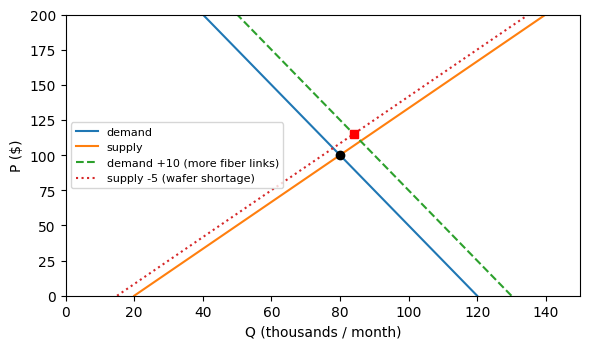

In [12]:
a, b, c, d = sp.symbols("a b c d", positive=True)
m = L.market(a, b, c, d)
display(m["A"], sp.Eq(sp.Symbol("P^*"), m["P"]), sp.Eq(sp.Symbol("Q^*"), m["Q"]))
pm = L.PHOTONICS_MARKET
s = L.market_shift(**pm, demand_shift=10, supply_shift=-5)
print("SymPy: before (P, Q) =", s["before"], " after =", tuple(float(v) for v in s["after"]))
try:
    print("gcc  :", L.market_c(**pm, demand_shift=10, supply_shift=-5))
except RuntimeError as e:
    print("gcc unavailable:", e)
Pg = np.linspace(0, 200, 200)
fig, ax = plt.subplots(figsize=(6, 3.6))
ax.plot(pm["a"] - pm["b"] * Pg, Pg, label="demand"); ax.plot(pm["c"] + pm["d"] * Pg, Pg, label="supply")
ax.plot(pm["a"] + 10 - pm["b"] * Pg, Pg, "--", label="demand +10 (more fiber links)")
ax.plot(pm["c"] - 5 + pm["d"] * Pg, Pg, ":", label="supply -5 (wafer shortage)")
ax.plot(*[float(v) for v in s["before"][::-1]], "ko"); ax.plot(*[float(v) for v in s["after"][::-1]], "rs")
ax.set(xlabel="Q (thousands / month)", ylabel="P ($)", xlim=(0, 150), ylim=(0, 200)); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

In [13]:
%%lean market
/-! ## 5. Supply and demand -/

theorem equilibrium_price (a b c d P Q : ℝ) (hbd : b + d ≠ 0)
    (hD : Q = a - b * P) (hS : Q = c + d * P) : P = (a - c) / (b + d) := by
  rw [eq_div_iff hbd]
  linear_combination hD - hS

theorem demand_shift_raises_price (a b c d δ : ℝ) (hb : 0 < b) (hd : 0 < d) (hδ : 0 < δ) :
    (a + δ - c) / (b + d) - (a - c) / (b + d) = δ / (b + d) ∧ 0 < δ / (b + d) := by
  refine ⟨by ring, by positivity⟩

**Lean cell `market`** (collected; compiled by `%lean_check`)
```lean
/-! ## 5. Supply and demand -/

theorem equilibrium_price (a b c d P Q : ℝ) (hbd : b + d ≠ 0)
    (hD : Q = a - b * P) (hS : Q = c + d * P) : P = (a - c) / (b + d) := by
  rw [eq_div_iff hbd]
  linear_combination hD - hS

theorem demand_shift_raises_price (a b c d δ : ℝ) (hb : 0 < b) (hd : 0 < d) (hδ : 0 < δ) :
    (a + δ - c) / (b + d) - (a - c) / (b + d) = δ / (b + d) ∧ 0 < δ / (b + d) := by
  refine ⟨by ring, by positivity⟩
```

## 6. Attention in torch is linear algebra plus softmax

out = softmax(QKᵀ/√d) V. Each output row is a weighted average of the rows of V, because the
softmax weights are positive and sum to 1 (Lean proves both). Adding a constant to a row of
scores changes nothing (`softmax_shift`), which is why torch subtracts the row max before exp:
same answer, no overflow. Syntax to remember:

```python
scores = Q @ K.transpose(-2, -1) / math.sqrt(d)     # (n_q, n_k)
weights = torch.softmax(scores, dim=-1)              # each row sums to 1
out = weights @ V                                    # (n_q, d_v)
```

In [14]:
w, total, shift = L.softmax_symbolic(3)
display(w[0], sp.Eq(sp.Symbol("sum"), total))
print("shift by c changes each weight by:", shift)
try:
    display(pd.Series(L.check_attention(), name="result"))
except ImportError:
    print("torch not installed: skipped")

shift by c changes each weight by: [0, 0, 0]


max |ours - torch|                          0.0
causal max |ours - torch|                   0.0
rows sum to 1                              True
weights > 0                                True
permute queries -> permuted output         True
causal: no weight on the future            True
output in convex hull of V (per column)    True
Name: result, dtype: object

In [15]:
%%lean softmax
/-! ## 6. Softmax: the attention weights -/

theorem softmax_pos {n : ℕ} [NeZero n] (x : Fin n → ℝ) (i : Fin n) :
    0 < Real.exp (x i) / ∑ j, Real.exp (x j) :=
  div_pos (Real.exp_pos _) (Finset.sum_pos (fun j _ => Real.exp_pos (x j)) Finset.univ_nonempty)

theorem softmax_sum_one {n : ℕ} [NeZero n] (x : Fin n → ℝ) :
    ∑ i, Real.exp (x i) / ∑ j, Real.exp (x j) = 1 := by
  rw [← Finset.sum_div]
  exact div_self (Finset.sum_pos (fun j _ => Real.exp_pos (x j)) Finset.univ_nonempty).ne'

theorem softmax_shift {n : ℕ} (x : Fin n → ℝ) (c : ℝ) (i : Fin n) :
    Real.exp (x i + c) / ∑ j, Real.exp (x j + c) = Real.exp (x i) / ∑ j, Real.exp (x j) := by
  simp only [Real.exp_add]
  rw [← Finset.sum_mul, mul_div_mul_right _ _ (Real.exp_pos c).ne']

**Lean cell `softmax`** (collected; compiled by `%lean_check`)
```lean
/-! ## 6. Softmax: the attention weights -/

theorem softmax_pos {n : ℕ} [NeZero n] (x : Fin n → ℝ) (i : Fin n) :
    0 < Real.exp (x i) / ∑ j, Real.exp (x j) :=
  div_pos (Real.exp_pos _) (Finset.sum_pos (fun j _ => Real.exp_pos (x j)) Finset.univ_nonempty)

theorem softmax_sum_one {n : ℕ} [NeZero n] (x : Fin n → ℝ) :
    ∑ i, Real.exp (x i) / ∑ j, Real.exp (x j) = 1 := by
  rw [← Finset.sum_div]
  exact div_self (Finset.sum_pos (fun j _ => Real.exp_pos (x j)) Finset.univ_nonempty).ne'

theorem softmax_shift {n : ℕ} (x : Fin n → ℝ) (c : ℝ) (i : Fin n) :
    Real.exp (x i + c) / ∑ j, Real.exp (x j + c) = Real.exp (x i) / ∑ j, Real.exp (x j) := by
  simp only [Real.exp_add]
  rw [← Finset.sum_mul, mul_div_mul_right _ _ (Real.exp_pos c).ne']
```

## 7. Compile every Lean cell

In [16]:
%%lean footer
end LinAlg

**Lean cell `footer`** (collected; compiled by `%lean_check`)
```lean
end LinAlg
```

In [17]:
lean_result = %lean_check
from dgs.lean_magic import SESSION
display(pd.DataFrame({"Lean theorem": SESSION.last.theorems, "status": SESSION.last.status}))

Lean status: VERIFIED  (lake env lean exit 0, no errors, no sorry), 10 s


,Lean theorem,status
0,det_product,VERIFIED
1,transpose_product,VERIFIED
2,trace_cyclic,VERIFIED
3,det_two_by_two,VERIFIED
4,kernel_midpoint,VERIFIED
5,cauchy_schwarz_2d,VERIFIED
6,complement_projection,VERIFIED
7,equilibrium_price,VERIFIED
8,demand_shift_raises_price,VERIFIED
9,softmax_pos,VERIFIED
